# 09 · Rotations: matrices, Euler angles, axis-angle, quaternions

In [1]:
import mujoco, numpy as np, matplotlib.pyplot as plt
from scipy.spatial.transform import Rotation as R, Slerp
from vlacourse import TableTop, show_images
from vlacourse.panda import solve_ik

def rot_x(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])

def rot_y(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])

def rot_z(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

def quat_mul(a, b):
    w1, x1, y1, z1 = a
    w2, x2, y2, z2 = b
    return np.array([w1*w2 - x1*x2 - y1*y2 - z1*z2, w1*x2 + x1*w2 + y1*z2 - z1*y2,
                     w1*y2 - x1*z2 + y1*w2 + z1*x2, w1*z2 + x1*y2 - y1*x2 + z1*w2])

def axis_angle_quat(axis, angle):
    axis = np.asarray(axis, float) / np.linalg.norm(axis)
    return np.r_[np.cos(angle / 2), np.sin(angle / 2) * axis]

def quat_to_mat(q):
    m = np.zeros(9)
    mujoco.mju_quat2Mat(m, q)
    return m.reshape(3, 3)

def draw_frame(ax, Rm, origin=(0, 0, 0), label=""):
    for i, c in enumerate("rgb"):
        ax.quiver(*origin, *Rm[:, i], color=c, length=1)
    ax.text(*(np.array(origin) + 1.1 * Rm[:, 0]), label)

In [2]:
Rm = rot_z(0.4) @ rot_y(-0.3) @ rot_x(1.1)
print("orthonormal:", np.allclose(Rm.T @ Rm, np.eye(3)), " det =", np.linalg.det(Rm).round(6))
print("inverse == transpose:", np.allclose(np.linalg.inv(Rm), Rm.T))
print("ZYX euler (yaw, pitch, roll):", R.from_matrix(Rm).as_euler("ZYX").round(4))

orthonormal: True  det = 1.0
inverse == transpose: True
ZYX euler (yaw, pitch, roll): [ 0.4 -0.3  1.1]


In [3]:
q1 = axis_angle_quat([0, 0, 1], 0.4)
q2 = axis_angle_quat([1, 0, 0], 1.1)
q12 = quat_mul(q1, q2)
mj = np.zeros(4); mujoco.mju_mulQuat(mj, q1, q2)
print("hand-written product == mujoco:", np.allclose(q12, mj))
print("q and -q are the same rotation:", np.allclose(quat_to_mat(q12), quat_to_mat(-q12)))
print("matrix from quat == Rz Rx:", np.allclose(quat_to_mat(q12), rot_z(0.4) @ rot_x(1.1)))
rv = np.zeros(3); mujoco.mju_quat2Vel(rv, q12, 1.0)
print("axis-angle (rotation vector):", rv.round(4), " |angle| =", np.linalg.norm(rv).round(4))

hand-written product == mujoco: True
q and -q are the same rotation: True
matrix from quat == Rz Rx: True
axis-angle (rotation vector): [1.0847 0.2199 0.3586]  |angle| = 1.1634


In [4]:
for pitch in [0.0, np.pi / 2]:
    a = R.from_euler("ZYX", [0.3, pitch, 0.0]).as_matrix()
    b = R.from_euler("ZYX", [0.0, pitch, -0.3]).as_matrix()
    print(f"pitch={pitch:.2f}: yaw=+0.3 vs roll=-0.3 give same matrix -> {np.allclose(a, b)}")

pitch=0.00: yaw=+0.3 vs roll=-0.3 give same matrix -> False
pitch=1.57: yaw=+0.3 vs roll=-0.3 give same matrix -> True


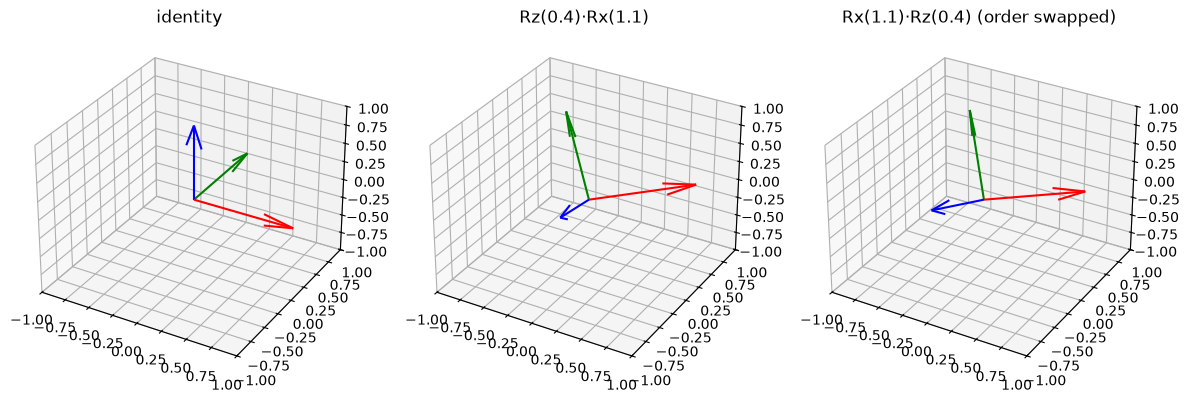

In [5]:
fig = plt.figure(figsize=(12, 4))
for k, (name, rot) in enumerate({"identity": np.eye(3), "Rz(0.4)·Rx(1.1)": Rm, "Rx(1.1)·Rz(0.4) (order swapped)": rot_x(1.1) @ rot_z(0.4)}.items()):
    ax = fig.add_subplot(1, 3, k + 1, projection="3d")
    draw_frame(ax, rot); ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_zlim(-1, 1); ax.set_title(name)
plt.tight_layout(); plt.show()

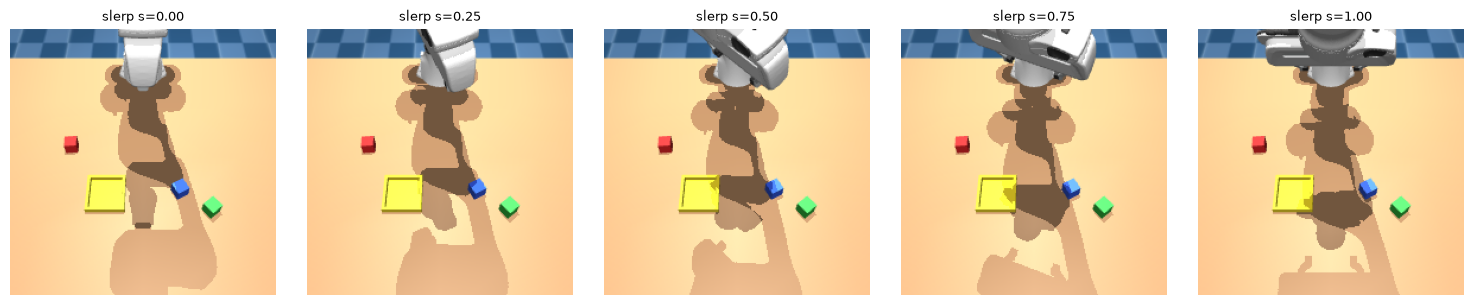

In [6]:
env = TableTop(cameras=("front",), seed=0)
p0, q0 = env.target_pos.copy(), env.target_quat.copy()
q_goal = quat_mul(axis_angle_quat([0, 0, 1], np.pi / 2), quat_mul(axis_angle_quat([1, 0, 0], 0.5), q0))
slerp = Slerp([0, 1], R.from_quat([np.r_[q0[1:], q0[0]], np.r_[q_goal[1:], q_goal[0]]]))
frames, q = [], env.q_cmd
for s in np.linspace(0, 1, 5):
    xyzw = slerp([s]).as_quat()[0]
    q, _ = solve_ik(env.model, env.data, p0, np.r_[xyzw[3], xyzw[:3]], q)
    env.data.qpos[:7] = q; mujoco.mj_forward(env.model, env.data)
    frames.append(env.render("front"))
show_images(frames, [f"slerp s={s:.2f}" for s in np.linspace(0, 1, 5)])